In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib
import matplotlib.pyplot as plt
import pickle
!pip install --upgrade arabic-reshaper
import arabic_reshaper

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
PICKLE_PATH = "/content/drive/MyDrive/AUT/Project/Features/DATA_MFCC30_MEL128.pkl"

In [ ]:
def load_data():
    with open(PICKLE_PATH, "rb") as input:
        DATA = pickle.load(input)

    X1 = np.array(DATA["mfccs"], dtype=np.float32)
    X2 = np.array(DATA["mel_spec"], dtype=np.float32)
    y1 = np.array(DATA["labels"]["instrument"], dtype=np.int8)
    y2 = np.array(DATA["labels"]["scale"], dtype=np.int8)

    return X1, X2, y1, y2

In [ ]:
def load_tmp_data(num_data=9000):

    X1 = np.random.randn(num_data, 216, 90).astype(np.float32)
    X2 = np.random.randn(num_data, 216, 128).astype(np.float32)
    y1 = np.random.randint(5, size=num_data, dtype=np.int8)
    y2 = np.random.randint(7, size=num_data, dtype=np.int8)

    return X1, X2, y1, y2

In [ ]:
def get_unique_labels(y1, y2):
  return np.array([[y1[i], y2[i]] for i in range(len(y1))])

In [ ]:
def prepare_dataset():
    X1, X2, y1, y2 = load_data()

    X1_train, X1_test, X2_train, X2_test, y1_train, y1_test, y2_train, y2_test = \
        train_test_split(X1, X2, y1, y2, test_size=0.15, shuffle=True, random_state=0)
                        #  stratify=get_unique_labels(y1, y2))

    X1_test, X1_val, X2_test, X2_val, y1_test, y1_val, y2_test, y2_val = \
        train_test_split(X1_test, X2_test, y1_test, y2_test, test_size=0.5, shuffle=True, random_state=0)
                        #  stratify=get_unique_labels(y1_test, y2_test))

    # X2: 4d array -> (num_samples, 216, 128, 1)
    X_train = (X1_train, X2_train[..., np.newaxis])
    X_test = (X1_test, X2_test[..., np.newaxis])
    X_val = (X1_val, X2_val[..., np.newaxis])

    Y_train = (y1_train, y2_train)
    Y_test = (y1_test, y2_test)
    Y_val = (y1_val, y2_val)

    return X_train, X_test, X_val, Y_train, Y_test, Y_val

In [ ]:
def data_distribution(Y):
  idx  =[0 for _ in range(5)]
  sdx = [0 for _ in range(7)]
  qdx = np.array([[0 for _ in range(5)] for _ in range(7)])

  Y1, Y2 = Y[0], Y[1]

  for (y1, y2) in zip(Y1, Y2):
    idx[y1] += 1
    sdx[y2] += 1
    qdx[y2][y1] += 1

  print("Distribution based on Insturment:")
  print(idx)

  print("\nDistribution based on Scale:")
  print(sdx)

  print("\nDistribution based on Insturment & Scale:")
  print(qdx)

  return idx, sdx, qdx

In [ ]:
X_train, X_test, X_val, Y_train, Y_test, Y_val = prepare_dataset()
idx, sdx, qdx = data_distribution(Y_train)

Distribution based on Insturment:
[1283, 1114, 2457, 1682, 1114]

Distribution based on Scale:
[1168, 1128, 1182, 1142, 884, 879, 1267]

Distribution based on Insturment & Scale:
[[170 139 473 227 159]
 [302 148 347 191 140]
 [170 146 357 372 137]
 [172 183 404 164 219]
 [135 177 180 235 157]
 [172 136 289 137 145]
 [162 185 407 356 157]]


In [ ]:
instuments_labels = ["تار", "کمانچه", "سنتور", "سه‌تار", "نی"]
scale_lables = ["شور", "سه‌گاه", "ماهور", "همایون", "راست‌ پنج‌گاه", "نوا", "چهارگاه"]

In [ ]:
def plotter(data_dist, data_labels, x_title, y_title, fig_size = (12,8), titles_fontsize = 18):
  plt.figure(figsize=(8,6))
  plt.bar(range(len(data_dist)), data_dist)
  plt.xticks(range(len(data_dist)), [arabic_reshaper.reshape(label)[::-1] for label in  data_labels])
  plt.xlabel('\n' + arabic_reshaper.reshape(x_title)[::-1], fontsize = titles_fontsize)
  plt.ylabel(arabic_reshaper.reshape(y_title)[::-1], fontsize = titles_fontsize, labelpad=20)
  plt.show()


In [ ]:
# idx[2] -= 100
# idx[3] -= 100
idx[1] -= 50

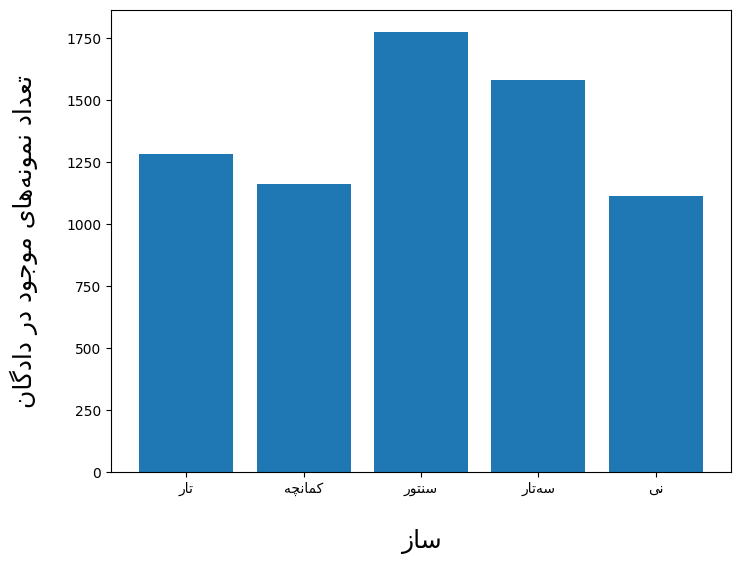

In [ ]:
plotter(idx, instuments_labels, "ساز", "تعداد نمونه‌های موجود در دادگان")

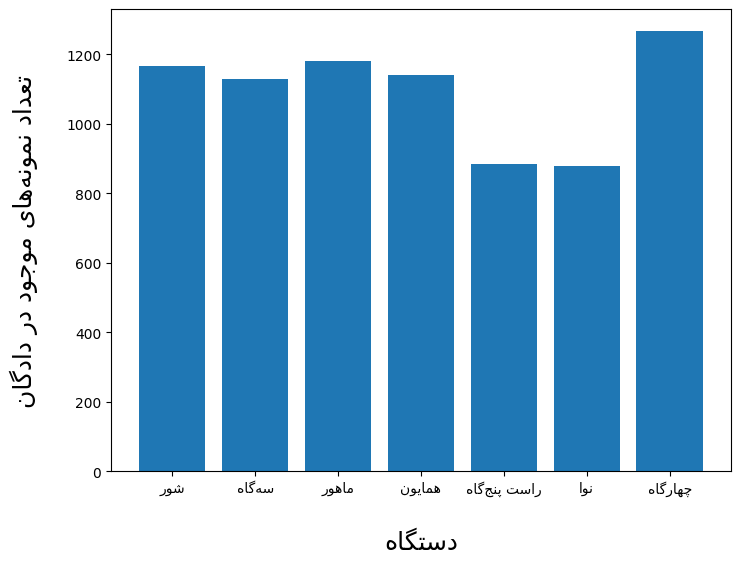

In [ ]:
plotter(sdx, scale_lables, "دستگاه", "تعداد نمونه‌های موجود در دادگان")